# Analysis of the dataset

## 0. Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipaddress
import urllib.parse
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

DATASET_PATH = r"C:\Users\User\Documents\Key Future Docs\Projects\Phising URL\dataset\new_data_urls.csv"

## 1. Load the dataset

In [2]:
df = pd.read_csv(DATASET_PATH)

df.reset_index(drop=True, inplace=True)
df.rename(columns={"status": "is_phishing"}, inplace=True)
df['is_phishing'] = df['is_phishing'] == 0

print("Total number of URLs in the dataset: ", len(df))
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Total number of URLs in the dataset:  822010


,url,is_phishing
0,bitworking.org/Aggie.html,False
1,wn.com/List_of_biographical_films,False
2,montrealgerman.blogspot.com/,False
6,examiner.com/silverbacks-in-atlanta/legendary-...,False
7,espn.go.com/nfl/team/rankings/_/name/oak/oakla...,False
8,http://www.yuzu-soft.com/,False
9,tools.ietf.org/html/rfc37,False
3,again-m12.ga,True
4,'institutocgr.com/web/plugins/content/Nets/Sik...,True
5,fraldas-bebe-conforto.com,True


In [3]:
num_phishing = df['is_phishing'].where(df['is_phishing'] == True).count()
num_legitimate = df['is_phishing'].where(df['is_phishing'] == False).count()
total = num_phishing + num_legitimate

print(f"The shape of the dataset is: {df.shape} with data types: {df.dtypes}")
print(f"Number of phishing URLs: {num_phishing}")
print(f"Number of legitimate URLs: {num_legitimate}")
print(f"Ratio of phishing to legitimate URLs: {num_phishing / num_legitimate:.4f} ({num_phishing}/{num_legitimate})")
print(f"Phishing to total ratio: {num_phishing / total:.4f}")
print(f"Number of URLs with NaN values: {df['url'].isnull().sum()}")
print(f"Number of labels with NaN values: {df['is_phishing'].isnull().sum()}")

The shape of the dataset is: (822010, 2) with data types: url            object
is_phishing      bool
dtype: object
Number of phishing URLs: 394982
Number of legitimate URLs: 427028
Ratio of phishing to legitimate URLs: 0.9250 (394982/427028)
Phishing to total ratio: 0.4805
Number of URLs with NaN values: 0
Number of labels with NaN values: 0


## 2. Split train & test periods

In [4]:
df = df.drop_duplicates('url')

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["is_phishing"], # to keep the same ratio of phishing and legitimate URLs in the train and test sets
)
train_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print(f"Train size: {len(train_df)}")
print(f"Test size: {len(test_df)}")

Train size: 646433
Test size: 161609


## 3. Split URLs into protocols, domains and paths

Using: https://docs.python.org/3/library/urllib.parse.html

In [5]:
def is_ip(string):
    try:
        string = string.strip('[]')
        ipaddress.ip_address(string)
        return True
    except:
        return False

result = []
for i, row in train_df.iterrows():
    raw_url = row['url']
    is_ip_result = is_ip(raw_url)
    if '://' not in raw_url and not is_ip_result:
        raw_url = 'http://' + raw_url
    try:
        parsed_url = urllib.parse.urlparse(raw_url)
    except:
        print(f"Error parsing URL: {raw_url}")
        result.append([None, None, None, None, None, False])
        continue
    protocol = parsed_url.scheme
    domain = parsed_url.netloc
    subdomains = parsed_url.netloc.split('.')[:-1]
    path = parsed_url.path
    tld = parsed_url.netloc.split('.')[-1]
    result.append([protocol, domain, subdomains, path, tld, is_ip_result])

train_df = pd.concat([train_df, pd.DataFrame(result, columns=['protocol', 'domain', 'subdomains', 'path', 'tld', 'is_ip'])], axis=1)
train_df.dropna(inplace=True)
print(train_df["is_ip"].value_counts())
print(train_df.loc[train_df["is_ip"], "url"].head(10))
train_df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Error parsing URL: http://¨RÊÃûaCóÞit×ßÂe-DÖØ+9YèÌçÏ¯·"0£ÙÕ.0ößF«7¹NRÙ{ccÉÄãéçx[Ä6a5Ñ³LÖíÜÉÀ£Òma¥yRX*0ÅÝ7×ÊÁÌo«Õs¶0kdèÑ&Ä"Ï¨mZ'àDM×ñXÚÒK"päî±h¬cAÊeK@4r"^'ÓFþ1*ËË PÞô;õ$úàÑ@þ=êWÑ"Ãhñ®ç^«Ýó^çRúUJ.<6CyÜFØrÿV2ôæýZãiiIb;¨Ëµu^ÍVy)­è»âýº+SÖáÃì?å6åÔ/
Error parsing URL: http://k¥¤ZM$:)ìLZ£.^rÕÕ{6eZAä¦v·¢ïöè®~QNgXx_BT°üÛP¼°­9sk%L0gPø·îh ÍÖxéovÝf-3Ó¹õ¥Â^¯ÝÀ\fâhuËS\&]`ñcL¤m!sÁF>øsgE¹)ó)â(2üfã).!÷ÿÞ<rDZÅ*¼/ e¼ËhúW+ï%»»;µÛ¦M5;ù\¸¥ßãV«û°z¦ö9Ì'Î| ¼ôªz"8#1¿D4A /[.|qt}Òåo#Ûõ*|Bv®U¬¢
Error parsing URL: http://AìfÙêìÝÕ2£»¸ü9nªÉ®'A½`ymî¹èDéIû-ÄXå¦²Â%js²ÍD^^Á*^ÜD-À%³;Óßñg\8+±Wnn@¾IßBëC[³3S7M(úJzª6¥HmÒ)fæ(þi¡d ùp
Error parsing URL: http://oÍÑOwEuÊÚÃß=nËß[j{2%.tñø­½½qx½NºPmx$Aì&ÝIhÂéc¶A9®cì3ßyiÚý~JÍf]$ö M¸°;xÃu0IÅ@xõe^cÃ ¸´ÞO7B~FrØ\<kÅb{T!Ìé	r?kX-YÇS@T)LeaÃ}°¡ùï4ºkïá2¢kEì¬ôfsçË×ÛQìê{o£UÜ§D©l½±±äâqôó¼-â0èÙ¦kvîdàQÎé

,url,is_phishing,protocol,domain,subdomains,path,tld,is_ip
0,www.whatsnextonline.com/wno/current.html,False,http,www.whatsnextonline.com,"[www, whatsnextonline]",/wno/current.html,com,False
6,montreal.ad/cartier,False,http,montreal.ad,[montreal],/cartier,ad,False
9,rossiterrelocation.com/,False,http,rossiterrelocation.com,[rossiterrelocation],/,com,False
1,154.16.3.202/bins/mirai.x86,True,http,154.16.3.202,"[154, 16, 3]",/bins/mirai.x86,202,False
2,victorcasino.com/8g74crec?mzRrtvJKj=qOCzPJHea,True,http,victorcasino.com,[victorcasino],/8g74crec,com,False
3,http://kathycannon.net/wp-content/themes/onlin...,True,http,kathycannon.net,[kathycannon],/wp-content/themes/online/verify/go.php,net,False
4,https://k31gfa.webwave.dev/,True,https,k31gfa.webwave.dev,"[k31gfa, webwave]",/,dev,False
5,mhgroup.cl,True,http,mhgroup.cl,[mhgroup],,cl,False
7,pastehtml.com/view/begsql915.html,True,http,pastehtml.com,[pastehtml],/view/begsql915.html,com,False
8,http://aalxoqxzmp.duckdns.org,True,http,aalxoqxzmp.duckdns.org,"[aalxoqxzmp, duckdns]",,org,False


# 4. Search for patterns in the dataset

In [6]:
def create_bar_plot(df_temp, column, title, limit_x=None, limit_y=None):
    phishing_counts = df_temp.where(df_temp['is_phishing'] == True).groupby(column)['is_phishing'].count()
    legitimate_counts = df_temp.where(df_temp['is_phishing'] == False).groupby(column)['is_phishing'].count()

    ratio = legitimate_counts / (phishing_counts + legitimate_counts)

    ax = ratio.plot(kind='bar', figsize=(10, 5))
    if limit_x is not None:
        ax.set_xlim(0, limit_x)
    if limit_y is not None:
        ax.set_ylim(0, limit_y)
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('% legitimate')
    plt.show()

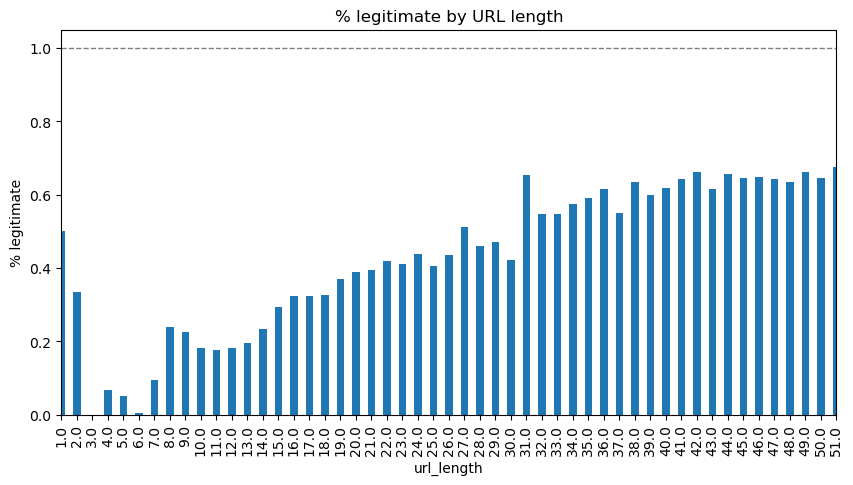

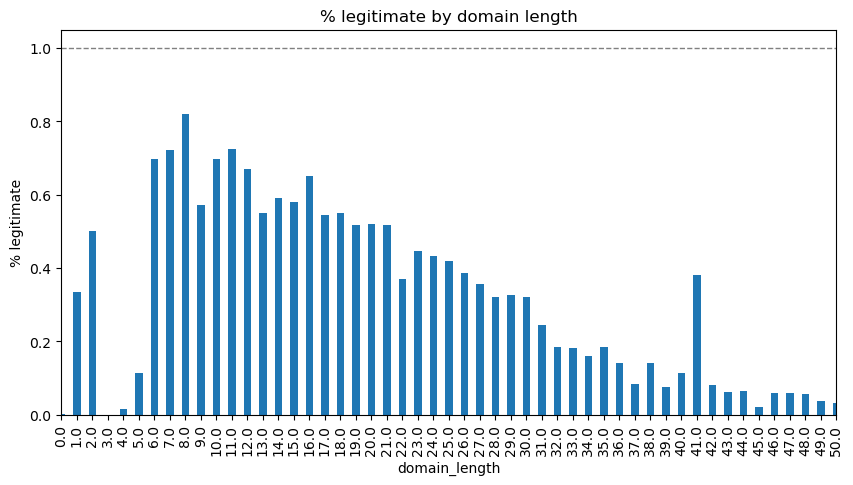

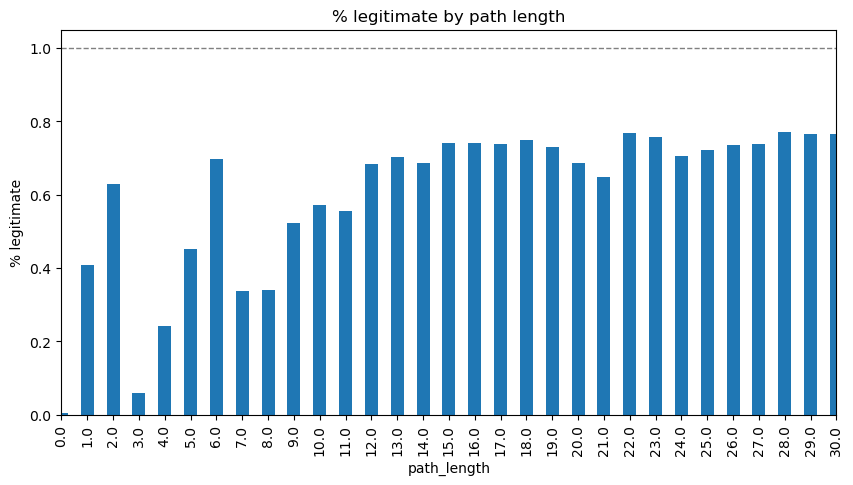

In [7]:
length_plots = train_df.copy()
length_plots['url_length'] = length_plots['url'].str.len()
create_bar_plot(length_plots, 'url_length', '% legitimate by URL length', 50)

length_plots['domain_length'] = length_plots['domain'].str.len()
create_bar_plot(length_plots, 'domain_length', '% legitimate by domain length', 50)

length_plots['path_length'] = length_plots['path'].str.len()
create_bar_plot(length_plots, 'path_length', '% legitimate by path length', 30)

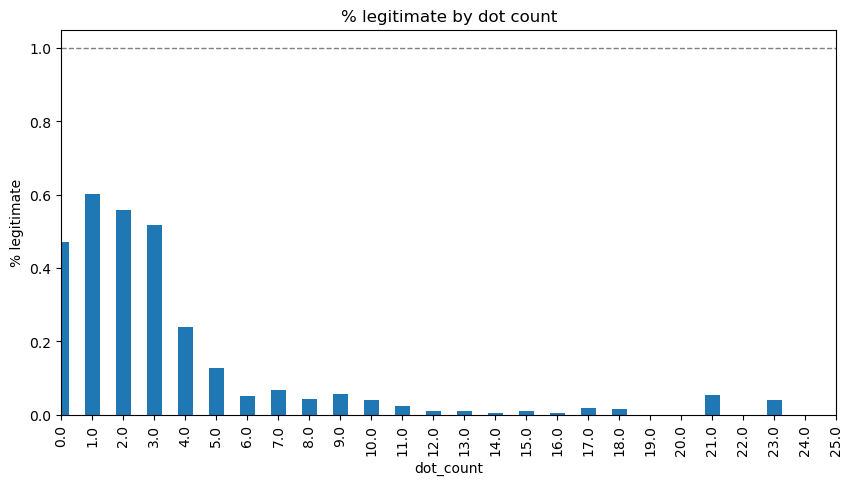

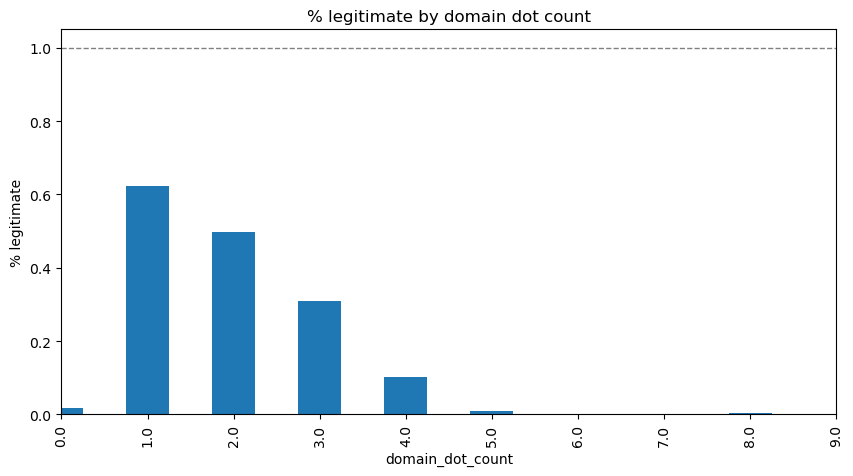

In [13]:
dot_plots = train_df.copy()
dot_plots['dot_count'] = dot_plots['url'].str.count(r'\.')
create_bar_plot(dot_plots, 'dot_count', '% legitimate by dot count', 25)

# per section dot count
dot_plots['domain_dot_count'] = dot_plots['domain'].str.count(r'\.')
create_bar_plot(dot_plots, 'domain_dot_count', '% legitimate by domain dot count', 9)

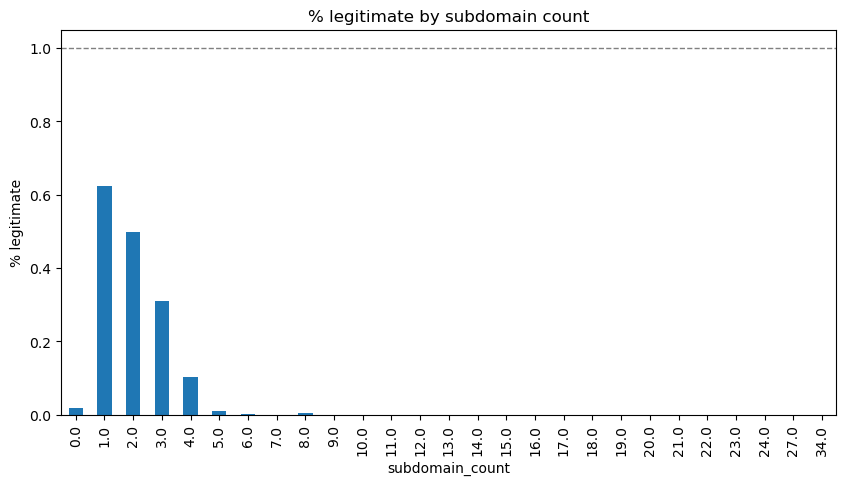

In [9]:
subdomain_plot = train_df.copy()
subdomain_plot['subdomain_count'] = subdomain_plot['subdomains'].str.len()
create_bar_plot(subdomain_plot, 'subdomain_count', '% legitimate by subdomain count')

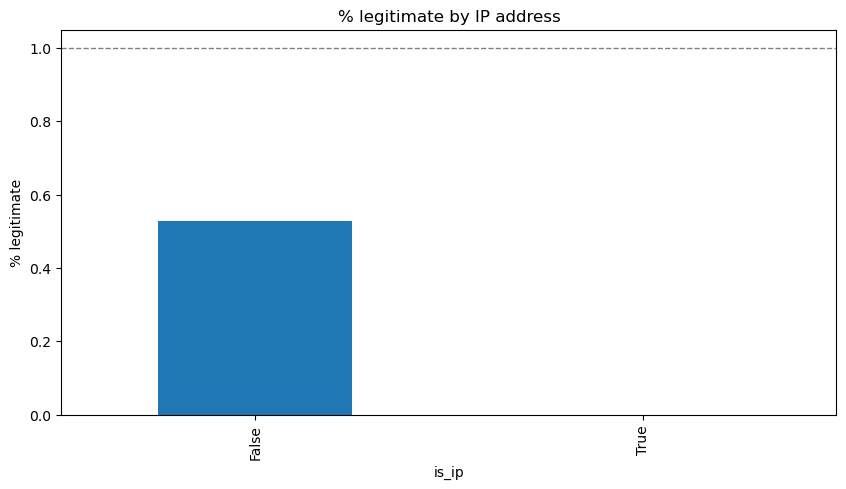

In [10]:
ip_plot = train_df.copy()
create_bar_plot(ip_plot, 'is_ip', '% legitimate by IP address')

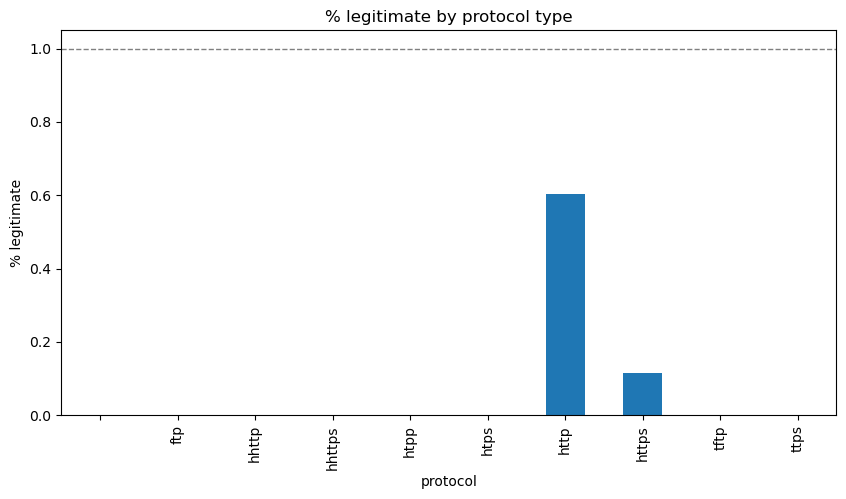

In [11]:
protocol_type_plot = train_df.copy()
protocol_type_plot = protocol_type_plot[~protocol_type_plot['protocol'].str.endswith('xxp', na=False)] # dropping a long incorrect protocol
create_bar_plot(protocol_type_plot, 'protocol', '% legitimate by protocol type')

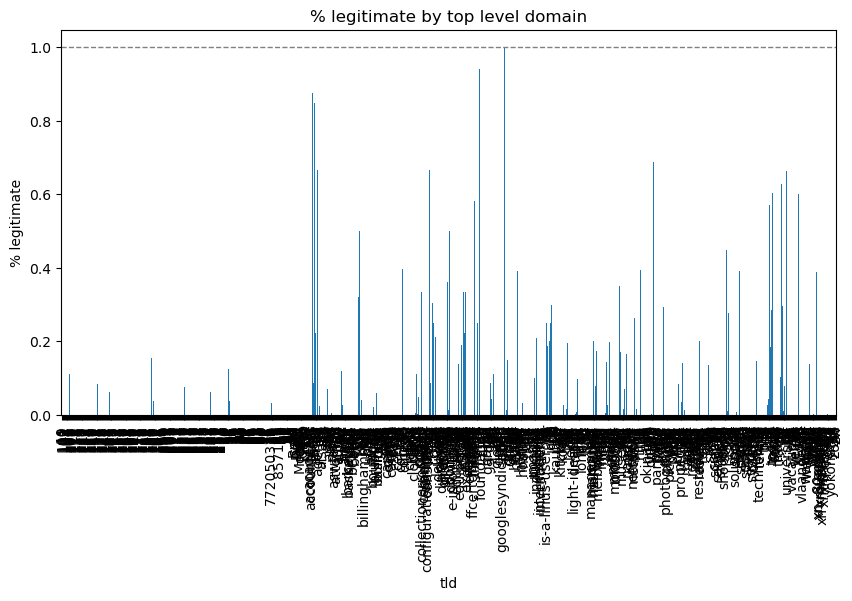

In [12]:
top_level_domain_plot = train_df.copy()
top_level_domain_plot = train_df[train_df['tld'].astype(str).str.fullmatch(r'[A-Za-z0-9-]{2,24}')]
create_bar_plot(top_level_domain_plot, 'tld', '% legitimate by top level domain')